## **Studi Kasus: Penerapan Python dan GIS untuk Analisis Prioritas Pemeliharaan Aset Jalan Menggunakan Google Colab**

Sebuah instansi pemerintah daerah memiliki sejumlah ruas jalan yang perlu dipantau dan dipelihara secara berkala. Setiap ruas jalan memiliki karakteristik yang berbeda, seperti lokasi geografis berdasarkan koordinat latitude dan longitude, tingkat kerusakan, volume lalu lintas, panjang jalan, serta estimasi biaya perbaikan. Namun, instansi tersebut mengalami kesulitan dalam menentukan prioritas pemeliharaan karena data aset belum dianalisis secara terintegrasi. Sementara itu, anggaran yang tersedia terbatas sehingga perbaikan perlu dilakukan berdasarkan tingkat urgensi dan kebutuhan. Untuk mengatasi permasalahan tersebut, mahasiswa diminta mengembangkan simulasi sistem analisis aset jalan menggunakan Python melalui Google Colab dengan memanfaatkan library Pandas untuk pengolahan data, Matplotlib untuk visualisasi grafik, dan Folium untuk menampilkan peta interaktif.

Dalam studi kasus ini, mahasiswa menggunakan dataset sintetis yang terdiri atas sepuluh ruas jalan di sekitar Kota Bengkulu. Setiap data mencakup identitas aset, koordinat geografis, tingkat kerusakan dengan skala 1–5, volume lalu lintas dengan skala 1–5, panjang jalan dalam kilometer, dan estimasi biaya perbaikan dalam juta rupiah. Data tersebut kemudian diperiksa untuk mengidentifikasi nilai kosong, data duplikat, serta nilai yang berada di luar rentang yang ditentukan. Setelah proses pemeriksaan, sistem menghitung skor prioritas pemeliharaan dengan memberikan bobot 70% pada tingkat kerusakan dan 30% pada volume lalu lintas. Skor yang dihasilkan digunakan untuk mengelompokkan aset ke dalam kategori prioritas sangat tinggi, tinggi, sedang, dan rendah. Hasil analisis kemudian divisualisasikan melalui grafik dan peta interaktif sehingga pengguna dapat melihat lokasi aset, tingkat kerusakan, kategori prioritas, serta estimasi biaya perbaikan pada setiap ruas jalan.

Tahap selanjutnya adalah melakukan simulasi alokasi anggaran sebesar Rp400 juta untuk menentukan ruas jalan yang dapat direkomendasikan untuk diperbaiki berdasarkan urutan skor prioritas dan biaya yang tersedia. Selain itu, hasil analisis dapat dimanfaatkan sebagai bahan bagi AI untuk menyusun ringkasan, menjelaskan alasan penentuan prioritas, dan memberikan rekomendasi tindak lanjut. AI dalam studi kasus ini berfungsi sebagai alat bantu interpretasi, bukan sebagai pengganti validasi data lapangan. Melalui penerapan tersebut, mahasiswa diharapkan memahami bagaimana teknologi GIS, Python, cloud computing melalui Google Colab, dan AI dapat diintegrasikan dalam alur kerja pengelolaan aset. Studi kasus ini juga menunjukkan bahwa kebutuhan industri tidak hanya menuntut kemampuan pemrograman, tetapi juga pemahaman terhadap pengelolaan data, analisis spasial, penyelesaian masalah, serta penyampaian hasil analisis untuk mendukung pengambilan keputusan. Perlu diperhatikan bahwa koordinat dan data yang digunakan hanya untuk simulasi pembelajaran, sehingga hasilnya tidak dapat dijadikan dasar penentuan perbaikan jalan yang sebenarnya.

=== DATA AWAL ASET JALAN ===


,id_aset,nama_jalan,latitude,longitude,kerusakan,lalu_lintas,panjang_km,biaya_juta
0,J001,Jalan A,-3.790,102.260,5,5,1.2,120
1,J002,Jalan B,-3.800,102.270,4,4,0.8,80
2,J003,Jalan C,-3.810,102.280,3,5,1.5,150
3,J004,Jalan D,-3.780,102.290,5,3,2.0,200
4,J005,Jalan E,-3.820,102.250,2,2,0.7,70
5,J006,Jalan F,-3.795,102.300,4,5,1.0,100
6,J007,Jalan G,-3.805,102.240,5,4,1.8,180
7,J008,Jalan H,-3.815,102.310,1,2,0.5,50
8,J009,Jalan I,-3.785,102.265,3,3,1.1,110
9,J010,Jalan J,-3.825,102.275,4,5,1.4,140



=== PEMERIKSAAN DATA ===
Jumlah nilai kosong: 0
Jumlah ID aset duplikat: 0
Jumlah baris valid: 10
Jumlah baris tidak valid: 0

=== HASIL ANALISIS PRIORITAS ===


,id_aset,nama_jalan,kerusakan,lalu_lintas,skor_prioritas,kategori,biaya_juta
0,J001,Jalan A,5,5,5.0,Sangat Tinggi,120
1,J007,Jalan G,5,4,4.7,Sangat Tinggi,180
2,J004,Jalan D,5,3,4.4,Tinggi,200
3,J010,Jalan J,4,5,4.3,Tinggi,140
4,J006,Jalan F,4,5,4.3,Tinggi,100
5,J002,Jalan B,4,4,4.0,Tinggi,80
6,J003,Jalan C,3,5,3.6,Tinggi,150
7,J009,Jalan I,3,3,3.0,Sedang,110
8,J005,Jalan E,2,2,2.0,Rendah,70
9,J008,Jalan H,1,2,1.3,Rendah,50


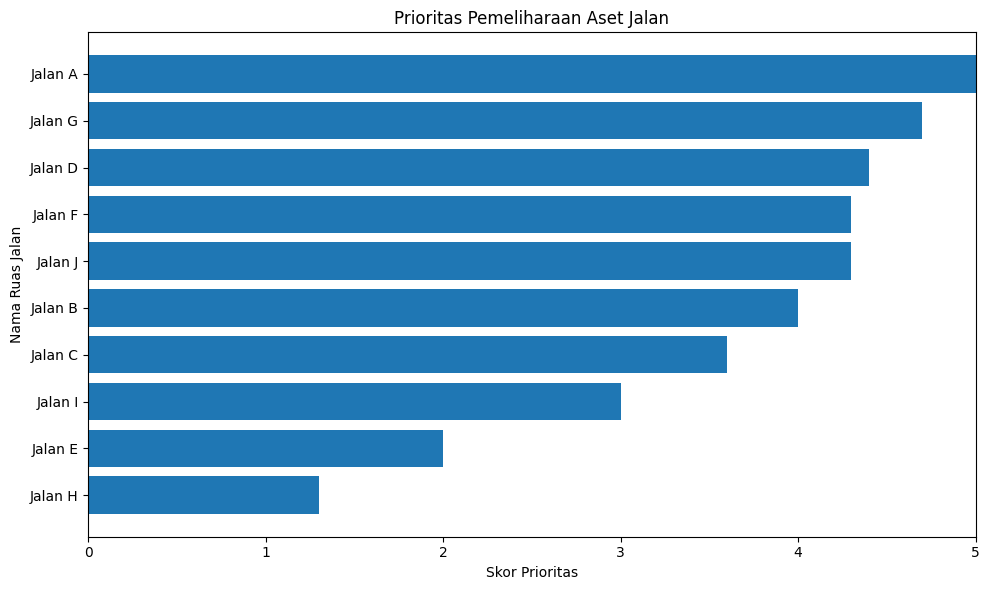


=== HASIL SIMULASI ANGGARAN ===
Anggaran tersedia: Rp400 juta
Total biaya terpilih: Rp400 juta
Sisa anggaran: Rp0 juta


,id_aset,nama_jalan,skor_prioritas,kategori,biaya_juta
0,J001,Jalan A,5.0,Sangat Tinggi,120
6,J007,Jalan G,4.7,Sangat Tinggi,180
5,J006,Jalan F,4.3,Tinggi,100



Catatan: Dataset dan koordinat hanya simulasi.


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import folium
from IPython.display import display

# 1. Membuat dataset sintetis aset jalan di sekitar Kota Bengkulu
data = {
    "id_aset": [f"J{i:03d}" for i in range(1, 11)],
    "nama_jalan": [f"Jalan {chr(64+i)}" for i in range(1, 11)],
    "latitude": [
        -3.790, -3.800, -3.810, -3.780, -3.820,
        -3.795, -3.805, -3.815, -3.785, -3.825
    ],
    "longitude": [
        102.260, 102.270, 102.280, 102.290, 102.250,
        102.300, 102.240, 102.310, 102.265, 102.275
    ],
    "kerusakan": [5, 4, 3, 5, 2, 4, 5, 1, 3, 4],
    "lalu_lintas": [5, 4, 5, 3, 2, 5, 4, 2, 3, 5],
    "panjang_km": [1.2, 0.8, 1.5, 2.0, 0.7, 1.0, 1.8, 0.5, 1.1, 1.4],
    "biaya_juta": [120, 80, 150, 200, 70, 100, 180, 50, 110, 140]
}

df = pd.DataFrame(data)

print("=== DATA AWAL ASET JALAN ===")
display(df)

# 2. Pemeriksaan kualitas data
print("\n=== PEMERIKSAAN DATA ===")
print("Jumlah nilai kosong:", df.isnull().sum().sum())
print("Jumlah ID aset duplikat:", df["id_aset"].duplicated().sum())

valid = (
    df["latitude"].between(-90, 90)
    & df["longitude"].between(-180, 180)
    & df["kerusakan"].between(1, 5)
    & df["lalu_lintas"].between(1, 5)
    & (df["panjang_km"] > 0)
    & (df["biaya_juta"] >= 0)
)

print("Jumlah baris valid:", valid.sum())
print("Jumlah baris tidak valid:", (~valid).sum())

# Hanya menggunakan baris yang lolos validasi
df = df.loc[valid].drop_duplicates(
    subset="id_aset"
).copy()

# 3. Menghitung skor dan kategori prioritas
df["skor_prioritas"] = (
    0.7 * df["kerusakan"]
    + 0.3 * df["lalu_lintas"]
)

def tentukan_kategori(skor):
    if skor >= 4.5:
        return "Sangat Tinggi"
    elif skor >= 3.5:
        return "Tinggi"
    elif skor >= 2.5:
        return "Sedang"
    return "Rendah"

df["kategori"] = df["skor_prioritas"].apply(
    tentukan_kategori
)

hasil = df.sort_values(
    "skor_prioritas", ascending=False
).reset_index(drop=True)

print("\n=== HASIL ANALISIS PRIORITAS ===")
display(
    hasil[[
        "id_aset", "nama_jalan", "kerusakan",
        "lalu_lintas", "skor_prioritas", "kategori",
        "biaya_juta"
    ]]
)

# 4. Visualisasi grafik prioritas
plot_data = hasil.sort_values("skor_prioritas")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["nama_jalan"],
    plot_data["skor_prioritas"]
)
plt.xlabel("Skor Prioritas")
plt.ylabel("Nama Ruas Jalan")
plt.title("Prioritas Pemeliharaan Aset Jalan")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()


# 5. Membuat peta aset tanpa basemap eksternal
# Menghindari error 403 dari server tile OpenStreetMap

import folium
from IPython.display import display

pusat_bengkulu = [-3.800, 102.275]

peta = folium.Map(
    location=pusat_bengkulu,
    zoom_start=13,
    tiles=None
)

# Menambahkan latar belakang sederhana
folium.Rectangle(
    bounds=[[-3.84, 102.23], [-3.77, 102.32]],
    color="gray",
    weight=1,
    fill=True,
    fill_color="#f3f4f6",
    fill_opacity=0.6,
    tooltip="Area simulasi Kota Bengkulu"
).add_to(peta)

warna = {
    "Sangat Tinggi": "red",
    "Tinggi": "orange",
    "Sedang": "blue",
    "Rendah": "green"
}

for _, row in df.iterrows():
    informasi = f"""
    <b>ID Aset:</b> {row['id_aset']}<br>
    <b>Nama:</b> {row['nama_jalan']}<br>
    <b>Kerusakan:</b> {row['kerusakan']}/5<br>
    <b>Lalu lintas:</b> {row['lalu_lintas']}/5<br>
    <b>Skor prioritas:</b> {row['skor_prioritas']:.2f}<br>
    <b>Kategori:</b> {row['kategori']}<br>
    <b>Biaya:</b> Rp{row['biaya_juta']} juta
    """

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=8,
        color=warna[row["kategori"]],
        fill=True,
        fill_color=warna[row["kategori"]],
        fill_opacity=0.85,
        popup=folium.Popup(informasi, max_width=300),
        tooltip=row["nama_jalan"]
    ).add_to(peta)

# Legenda
legenda = """
<div style="
position: fixed; bottom: 30px; left: 30px; z-index: 9999;
background: white; padding: 12px; border: 1px solid gray;
border-radius: 6px; font-size: 13px;">
<b>Kategori Prioritas</b><br>
<span style="color:red">●</span> Sangat Tinggi<br>
<span style="color:orange">●</span> Tinggi<br>
<span style="color:blue">●</span> Sedang<br>
<span style="color:green">●</span> Rendah
</div>
"""

peta.get_root().html.add_child(
    folium.Element(legenda)
)

display(peta)


# 6. Simulasi alokasi anggaran
anggaran = 400  # Dalam juta rupiah
terpilih = []
total_biaya = 0

for _, row in hasil.iterrows():
    biaya = row["biaya_juta"]

    if total_biaya + biaya <= anggaran:
        terpilih.append(row["id_aset"])
        total_biaya += biaya

df["direkomendasikan"] = df["id_aset"].isin(terpilih)

print("\n=== HASIL SIMULASI ANGGARAN ===")
print(f"Anggaran tersedia: Rp{anggaran} juta")
print(f"Total biaya terpilih: Rp{total_biaya} juta")
print(f"Sisa anggaran: Rp{anggaran - total_biaya} juta")

display(
    df[df["direkomendasikan"]][[
        "id_aset", "nama_jalan",
        "skor_prioritas", "kategori", "biaya_juta"
    ]].sort_values("skor_prioritas", ascending=False)
)

print("\nCatatan: Dataset dan koordinat hanya simulasi.")


# **Kesimpulan**

Berdasarkan studi kasus penerapan Python dan GIS untuk analisis prioritas pemeliharaan aset jalan menggunakan Google Colab, dapat disimpulkan bahwa teknologi informasi dapat membantu proses pengelolaan data aset secara lebih sistematis, efisien, dan terukur. Melalui penggunaan library Pandas, data aset jalan dapat diolah dan diperiksa kualitasnya, sedangkan Matplotlib digunakan untuk memvisualisasikan hasil analisis dalam bentuk grafik dan Folium digunakan untuk menampilkan lokasi aset melalui peta interaktif. Perhitungan skor prioritas berdasarkan tingkat kerusakan dan volume lalu lintas membantu menentukan ruas jalan yang perlu mendapat perhatian lebih dahulu, sementara simulasi anggaran memberikan gambaran mengenai pemilihan aset yang dapat diperbaiki sesuai dengan keterbatasan dana.

Studi kasus ini juga menunjukkan bahwa pemanfaatan GIS, Python, cloud computing, dan AI dapat mendukung pengambilan keputusan dalam industri, khususnya pada bidang asset management dan analisis data spasial. Namun, hasil analisis tetap bergantung pada kualitas data, ketepatan metode, dan validasi kondisi di lapangan. Data sintetis yang digunakan dalam simulasi ini hanya bertujuan untuk pembelajaran dan belum dapat dijadikan dasar keputusan operasional. Oleh karena itu, mahasiswa perlu mengembangkan kemampuan teknis sekaligus memahami alur kerja, berpikir kritis, dan menginterpretasikan hasil analisis. Kemampuan tersebut menjadi bekal penting untuk menghadapi kebutuhan industri modern yang semakin mengandalkan data dan teknologi dalam menyelesaikan permasalahan nyata.